STEP 1: Create a 1-qubit circuit (initial state |0>)

     
  q: 
     
c: 1/
     

STEP 2: Apply S gate
S|0> = |0>, S|1> = i|1>


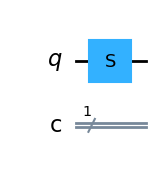


Statevector after S gate:
Statevector([1.+0.j, 0.+0.j],
            dims=(2,))

Theta (θ) = 0.000 rad
Phi (φ) = 0.000 rad
Bloch vector: x=0.000, y=0.000, z=1.000


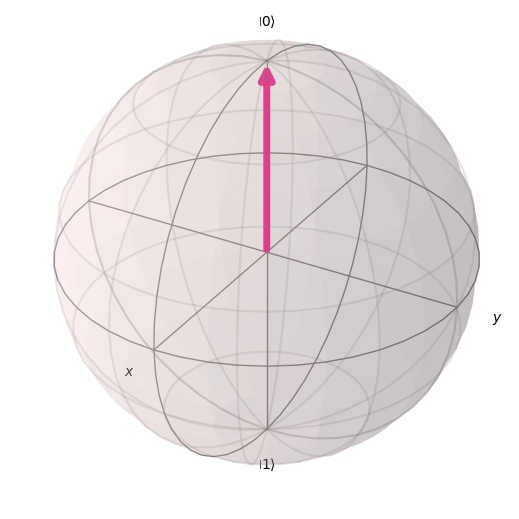

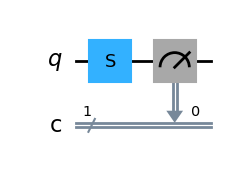


Measurement Results: {'0': 1024}


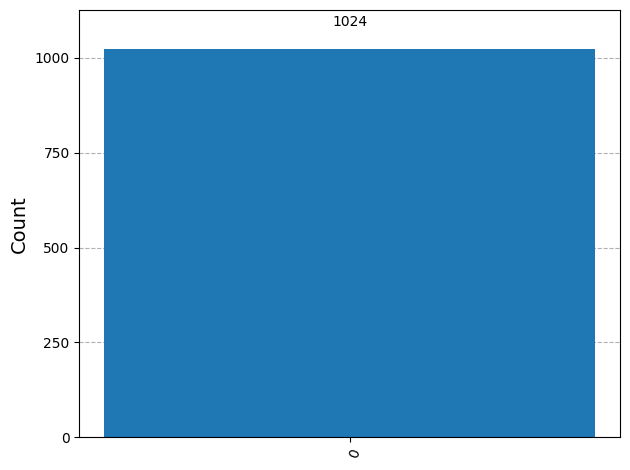


FINAL INTERPRETATION:
S gate adds a π/2 phase to |1>. If starting from |0>, measurement gives 0 with probability 1.
If starting from superposition states (like |+>), the vector rotates around Z-axis by φ = π/2.


In [6]:
# ============================================================
# FULL S Gate Demonstration in Qiskit
# ============================================================

%matplotlib inline
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_bloch_vector
from matplotlib import pyplot as plt

# ------------------------------------------------------------
# STEP 1: Create 1-qubit circuit
# ------------------------------------------------------------
print("STEP 1: Create a 1-qubit circuit (initial state |0>)\n")
qc = QuantumCircuit(1,1)
print(qc)

# ------------------------------------------------------------
# STEP 2: Apply S gate
# ------------------------------------------------------------
print("\nSTEP 2: Apply S gate")
print("S|0> = |0>, S|1> = i|1>")


qc.s(0)
qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 3: Statevector
# ------------------------------------------------------------
state = Statevector.from_instruction(qc)
print("\nStatevector after S gate:")
print(state)

# ------------------------------------------------------------
# STEP 4: Compute θ and φ for Bloch sphere
# ------------------------------------------------------------
a, b = state.data
theta = 2 * np.arccos(np.abs(a))
phi = np.angle(b) - np.angle(a)

print(f"\nTheta (θ) = {theta:.3f} rad")
print(f"Phi (φ) = {phi:.3f} rad")

# Convert to Bloch vector
x = np.sin(theta) * np.cos(phi)
y = np.sin(theta) * np.sin(phi)
z = np.cos(theta)

print(f"Bloch vector: x={x:.3f}, y={y:.3f}, z={z:.3f}")

plot_bloch_vector([x, y, z])
plt.show()

# ------------------------------------------------------------
# STEP 5: Measurement
# ------------------------------------------------------------
qc.measure(0,0)
qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 6: Simulation
# ------------------------------------------------------------
simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()
print("\nMeasurement Results:", counts)
plot_histogram(counts)
plt.show()

print("\nFINAL INTERPRETATION:")
print("S gate adds a π/2 phase to |1>. If starting from |0>, measurement gives 0 with probability 1.")
print("If starting from superposition states (like |+>), the vector rotates around Z-axis by φ = π/2.")